# Interpretación

## Preparación

In [38]:
from nbsetup import *
import statsmodels.formula.api as smf
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from pipeline import (Datos, UnidadesTratadas, UnidadesControl, Features, Emparejamiento,
                      muestra_comun, Panel, tabla_resultados, NIVELES_TESIS, COVARIABLES)
from pipeline.estimacion import COVARIABLES_FUERA, estrellas

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

RADIO = 300
datos = Datos()
emparejamientos, comunes = muestra_comun(datos)
e300 = emparejamientos[RADIO]
f300 = e300.features

_p = Panel(e300)
periodos, cortes = _p.periodos, _p.cortes
COV_DID = [c for c in COVARIABLES if c not in COVARIABLES_FUERA]

TRATADAS = [f"T{u}" for u in f300.tratadas.unidades.unidad_id]
CONTROLES_NAIVE = [f"C{u}" for u in f300.controles.seleccionar().unidad_id]
COMUNES = sorted(comunes)

ARCHIVO_BOOTSTRAP = DATA / "bootstrap-coeficientes.parquet"
if ARCHIVO_BOOTSTRAP.exists():
    boot = pd.read_parquet(ARCHIVO_BOOTSTRAP)
else:
    boot = pd.DataFrame({"radio": pd.Series(dtype=int), "nivel": pd.Series(dtype=str),
                         "especificacion": pd.Series(dtype=str),
                         "repeticion": pd.Series(dtype=int), "coef": pd.Series(dtype=float)})

print(f"tratadas: {len(TRATADAS)} | controles sin emparejar: {len(CONTROLES_NAIVE)} | "
      f"muestra común: {len(COMUNES)} | pares a {RADIO} m: {len(e300.pares)}")
if len(boot):
    print(f"bootstrap: {boot.groupby(['radio', 'nivel', 'especificacion']).ngroups} combinaciones, "
          f"{boot.repeticion.max() + 1:,} repeticiones")
else:
    print("bootstrap: todavía no existe data/bootstrap-coeficientes.parquet; "
          "los intervalos del bootstrap quedan vacíos")

tratadas: 99 | controles sin emparejar: 631 | muestra común: 93 | pares a 300 m: 93
bootstrap: 40 combinaciones, 2,000 repeticiones


In [39]:
def construir_panel(features, uids_tratadas, uids_controles, niveles=None):
    unidades = pd.DataFrame({
        "uid": list(uids_tratadas) + list(uids_controles),
        "tratado": [1] * len(uids_tratadas) + [0] * len(uids_controles),
    })
    inc = features.incidentes_asignados
    inc = inc[inc.uid.isin(unidades.uid)]
    if niveles is not None:
        inc = inc[inc.incident_level.isin(niveles)]
    i = np.searchsorted(cortes, inc.timestamp, side="right") - 1
    ok = (i >= 0) & (i < len(periodos))
    inc = inc[ok].assign(t=periodos.t.values[i[ok]])

    malla = pd.MultiIndex.from_product([unidades.uid, periodos.t], names=["uid", "t"])
    panel = (inc.groupby(["uid", "t"]).peso.sum()
             .reindex(malla, fill_value=0.0).rename("incidentes").reset_index()
             .merge(unidades, on="uid").merge(periodos[["t", "post"]], on="t"))
    assert abs(panel.incidentes.sum() - inc.peso.sum()) < 1e-6

    ids = sorted(int(u[1:]) for u in uids_tratadas)
    ov = features.tratadas.pares_traslapados
    ov = ov[ov.unidad_a.isin(ids) & ov.unidad_b.isin(ids)]
    pos = {u: k for k, u in enumerate(ids)}
    ady = coo_matrix((np.ones(len(ov)),
                      ([pos[a] for a in ov.unidad_a], [pos[b] for b in ov.unidad_b])),
                     shape=(len(ids),) * 2)
    _, etiqueta = connected_components(ady, directed=False)
    panel["cluster"] = panel.uid.map(
        {f"T{u}": f"G{c}" for u, c in zip(ids, etiqueta)}).fillna(panel.uid)

    cov = features.matriz.loc[unidades.uid, COV_DID]
    z = (cov - cov.mean()) / cov.std()
    panel = panel.merge(z.rename(columns=lambda c: f"z_{c}"), left_on="uid", right_index=True)
    for c in COV_DID:
        panel[f"{c}_post"] = panel[f"z_{c}"] * panel.post
    panel["treat_post"] = panel.tratado * panel.post
    return panel


ESPEC_1 = "incidentes ~ tratado + post + tratado:post"
ESPEC_2 = "incidentes ~ treat_post + C(uid) + C(t)"
ESPEC_3 = ("incidentes ~ treat_post + " + " + ".join(f"{c}_post" for c in COV_DID)
           + " + C(uid) + C(t)")


def estimar(panel, formula, agrupar="cluster"):
    if agrupar is None:
        return smf.ols(formula, data=panel).fit()
    return smf.ols(formula, data=panel).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(panel[agrupar])[0]})


def fila(paso, introduce, r, termino, panel, base, etiqueta_base):
    return {
        "paso": paso, "se introduce": introduce,
        "tratadas": panel[panel.tratado == 1].uid.nunique(),
        "controles": panel[panel.tratado == 0].uid.nunique(),
        "N": int(r.nobs), "coef": r.params[termino], "EE": r.bse[termino],
        "sig": estrellas(r.pvalues[termino]), "p": r.pvalues[termino],
        "base del %": etiqueta_base, "base": base,
        "% de la base": 100 * r.params[termino] / base,
    }


def media(panel, tratado, post):
    return panel[(panel.tratado == tratado) & (panel.post == post)].incidentes.mean()


In [52]:
ESPEC_3

'incidentes ~ treat_post + road_length_m_post + n_vialidades_post + carriles_ponderados_post + pct_acceso_controlado_post + pct_doble_sentido_post + pct_desnivel_post + n_niveles_post + afluencia_nivel_post + C(uid) + C(t)'

In [40]:
panel_emparejado = construir_panel(f300, e300.pares.tratada, e300.pares.control)
del_pipeline = Panel(e300)
esperado = del_pipeline.estimar(del_pipeline.especificaciones["(3) + covariables x post"])["coef"]
assert len(panel_emparejado) == len(del_pipeline.tabla)
assert abs(panel_emparejado.incidentes.sum() - del_pipeline.tabla.incidentes.sum()) < 1e-6
assert abs(estimar(panel_emparejado, ESPEC_3).params["treat_post"] - esperado) < 1e-9
print("construir_panel reproduce el panel y el coeficiente del pipeline")


construir_panel reproduce el panel y el coeficiente del pipeline


# Parte I — La estimación, a 300 m con todos los incidentes

In [41]:
escalera = []

## Paso 1 — Antes y después, solo tratadas

In [42]:
panel_tratadas = construir_panel(f300, TRATADAS, [])
r = estimar(panel_tratadas, "incidentes ~ post")
escalera.append(fila(1, "antes y después, solo tratadas", r, "post", panel_tratadas,
                     media(panel_tratadas, 1, 0), "tratadas, antes"))
pd.DataFrame([escalera[-1]]).round(4)


,paso,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
0,1,"antes y después, solo tratadas",99,0,7128,-0.9374,0.1613,***,0.0,"tratadas, antes",6.663,-14.0691


## Paso 2 — Tratadas contra controles, solo después

In [45]:
panel_naive = construir_panel(f300, TRATADAS, CONTROLES_NAIVE)
despues = panel_naive[panel_naive.post == 1]
r = estimar(despues, "incidentes ~ tratado")
escalera.append(fila(2, "tratadas contra controles, solo después", r, "tratado", despues,
                     media(panel_naive, 0, 1), "controles, después"))
pd.DataFrame([escalera[-1]]).round(4)


,paso,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
0,2,"tratadas contra controles, solo después",99,631,26280,2.2961,0.3103,***,0.0,"controles, después",3.4295,66.9501


## Paso 3 — Diferencia en diferencias, sin emparejar

In [46]:
r = estimar(panel_naive, ESPEC_1)
escalera.append(fila(3, "diferencia en diferencias", r, "tratado:post", panel_naive,
                     media(panel_naive, 0, 0), "controles, antes"))
print(r.params[["Intercept", "tratado", "post", "tratado:post"]].round(4).to_string())
pd.DataFrame([escalera[-1]]).round(4)


Intercept       3.8416
tratado         2.8214
post           -0.4121
tratado:post   -0.5253


,paso,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
0,3,diferencia en diferencias,99,631,52560,-0.5253,0.1646,***,0.0014,"controles, antes",3.8416,-13.675


## Paso 4 — Efectos fijos de unidad y de tiempo

In [48]:
r = estimar(panel_naive, ESPEC_2)
escalera.append(fila(4, "efectos fijos de unidad y tiempo", r, "treat_post", panel_naive,
                     media(panel_naive, 0, 0), "controles, antes"))
pd.DataFrame([escalera[-1]]).round(4)


,paso,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
0,4,efectos fijos de unidad y tiempo,99,631,52560,-0.5253,0.1659,***,0.0015,"controles, antes",3.8416,-13.675


## Paso 5 — Muestra común de 93 tratadas

In [49]:
panel_comun = construir_panel(f300, COMUNES, CONTROLES_NAIVE)
r = estimar(panel_comun, ESPEC_2)
escalera.append(fila(5, "muestra común de 93 tratadas", r, "treat_post", panel_comun,
                     media(panel_comun, 0, 0), "controles, antes"))
pd.DataFrame([escalera[-1]]).round(4)


,paso,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
0,5,muestra común de 93 tratadas,93,631,52128,-0.3884,0.1538,**,0.0116,"controles, antes",3.8416,-10.1101


## Paso 6 — Emparejamiento

In [12]:
r = estimar(panel_emparejado, ESPEC_2)
escalera.append(fila(6, "emparejamiento", r, "treat_post", panel_emparejado,
                     media(panel_emparejado, 0, 0), "controles, antes"))
pd.DataFrame([escalera[-1]]).round(4)


,paso,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
0,6,emparejamiento,93,93,13392,-0.1476,0.1981,,0.4565,"controles, antes",6.0194,-2.4512


## Paso 7 — Covariables × post

In [53]:
r7 = estimar(panel_emparejado, ESPEC_3)
escalera.append(fila(7, "covariables × post", r7, "treat_post", panel_emparejado,
                     media(panel_emparejado, 0, 0), "controles, antes"))
pd.DataFrame([escalera[-1]]).round(4)


,paso,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
0,7,covariables × post,93,93,13392,-0.1063,0.1808,,0.5566,"controles, antes",6.0194,-1.7664


## La escalera de la estimación

In [14]:
escalera_estimacion = pd.DataFrame(escalera).set_index("paso")
escalera_estimacion.round(4)


,se introduce,tratadas,controles,N,coef,EE,sig,p,base del %,base,% de la base
paso,,,,,,,,,,,
1,"antes y después, solo tratadas",99,0,7128,-0.9374,0.1613,***,0.0000,"tratadas, antes",6.6630,-14.0691
2,"tratadas contra controles, solo después",99,631,26280,2.2961,0.3103,***,0.0000,"controles, después",3.4295,66.9501
3,diferencia en diferencias,99,631,52560,-0.5253,0.1646,***,0.0014,"controles, antes",3.8416,-13.6750
4,efectos fijos de unidad y tiempo,99,631,52560,-0.5253,0.1659,***,0.0015,"controles, antes",3.8416,-13.6750
5,muestra común de 93 tratadas,93,631,52128,-0.3884,0.1538,**,0.0116,"controles, antes",3.8416,-10.1101
6,emparejamiento,93,93,13392,-0.1476,0.1981,,0.4565,"controles, antes",6.0194,-2.4512
7,covariables × post,93,93,13392,-0.1063,0.1808,,0.5566,"controles, antes",6.0194,-1.7664


# Parte II — La incertidumbre, sobre el paso 7

In [15]:
incertidumbre = []
coef7 = r7.params["treat_post"]
base7 = media(panel_emparejado, 0, 0)


def fila_analitica(paso, introduce, agrupar):
    r = estimar(panel_emparejado, ESPEC_3, agrupar=agrupar)
    bajo, alto = r.conf_int().loc["treat_post"]
    return {"paso": paso, "se introduce": introduce, "coef": r.params["treat_post"],
            "EE": r.bse["treat_post"], "p": r.pvalues["treat_post"],
            "sig": estrellas(r.pvalues["treat_post"]),
            "clusters": panel_emparejado[agrupar].nunique() if agrupar else None,
            "IC bajo": bajo, "IC alto": alto,
            "IC bajo %": 100 * bajo / base7, "IC alto %": 100 * alto / base7}


## Paso 8 — Sin agrupar

In [16]:
incertidumbre.append(fila_analitica(8, "sin agrupar", None))
pd.DataFrame([incertidumbre[-1]]).round(4)


,paso,se introduce,coef,EE,p,sig,clusters,IC bajo,IC alto,IC bajo %,IC alto %
0,8,sin agrupar,-0.1063,0.0935,0.2553,,None,-0.2895,0.0769,-4.8097,1.2769


## Paso 9 — Agrupado por unidad

In [17]:
incertidumbre.append(fila_analitica(9, "agrupado por unidad", "uid"))
pd.DataFrame([incertidumbre[-1]]).round(4)


,paso,se introduce,coef,EE,p,sig,clusters,IC bajo,IC alto,IC bajo %,IC alto %
0,9,agrupado por unidad,-0.1063,0.1722,0.537,,186,-0.4439,0.2312,-7.3739,3.8411


## Paso 10 — Agrupado por componente traslapada

In [18]:
incertidumbre.append(fila_analitica(10, "agrupado por componente traslapada", "cluster"))
pd.DataFrame([incertidumbre[-1]]).round(4)


,paso,se introduce,coef,EE,p,sig,clusters,IC bajo,IC alto,IC bajo %,IC alto %
0,10,agrupado por componente traslapada,-0.1063,0.1808,0.5566,,165,-0.4608,0.2481,-7.6547,4.1218


## Paso 11 — Bootstrap del proceso completo

In [62]:
b = boot.query("radio == @RADIO and nivel == 'general' and especificacion == '(3)'").coef
bajo, alto = np.percentile(b, [2.5, 97.5]) if len(b) else (np.nan, np.nan)
incertidumbre.append({
    "paso": 11, "se introduce": "bootstrap del proceso completo", "coef": coef7,
    "EE": b.std(ddof=1) if len(b) else np.nan, "p": None, "sig": "", "clusters": None,
    "IC bajo": bajo, "IC alto": alto,
    "IC bajo %": 100 * bajo / base7, "IC alto %": 100 * alto / base7,
    "media bootstrap": b.mean() if len(b) else np.nan,
    "percentil del estimado": 100 * (b < coef7).mean() if len(b) else np.nan,
    "repeticiones": len(b),
})
pd.DataFrame([incertidumbre[-1]]).round(4).fillna("-")


,paso,se introduce,coef,EE,p,sig,clusters,IC bajo,IC alto,IC bajo %,IC alto %,media bootstrap,percentil del estimado,repeticiones
0,11,bootstrap del proceso completo,-0.1063,0.1294,-,,-,-0.3637,0.1322,-6.0415,2.1963,-0.1155,52.9,2000


## La escalera de la incertidumbre

In [60]:
escalera_incertidumbre = pd.DataFrame(incertidumbre).set_index("paso")
escalera_incertidumbre["cruza cero"] = ((escalera_incertidumbre["IC bajo"] < 0)
                                        & (escalera_incertidumbre["IC alto"] > 0)).replace({True:"sí"})
escalera_incertidumbre.round(4).fillna('-')


,se introduce,coef,EE,p,sig,clusters,IC bajo,IC alto,IC bajo %,IC alto %,media bootstrap,percentil del estimado,repeticiones,cruza cero
paso,,,,,,,,,,,,,,
8,sin agrupar,-0.1063,0.0935,0.2553,,-,-0.2895,0.0769,-4.8097,1.2769,-,-,-,sí
9,agrupado por unidad,-0.1063,0.1722,0.537,,186.0,-0.4439,0.2312,-7.3739,3.8411,-,-,-,sí
10,agrupado por componente traslapada,-0.1063,0.1808,0.5566,,165.0,-0.4608,0.2481,-7.6547,4.1218,-,-,-,sí
11,bootstrap del proceso completo,-0.1063,0.1294,-,,-,-0.3637,0.1322,-6.0415,2.1963,-0.1155,52.9,2000.0,sí


# Parte III — Resultados

In [75]:
resultados = tabla_resultados(emparejamientos)
NOMBRE = {"(1) sin efectos fijos": "(1)", "(2) + EF unidad y tiempo": "(2)",
          "(3) + covariables x post": "(3)"}
resultados["espec"] = resultados.especificacion.map(NOMBRE)

if len(boot):
    ic = (boot.groupby(["radio", "nivel", "especificacion"]).coef
          .agg(EE_bootstrap=lambda c: c.std(ddof=1),
               ic_bajo=lambda c: np.percentile(c, 2.5),
               ic_alto=lambda c: np.percentile(c, 97.5))
          .reset_index().rename(columns={"especificacion": "espec"}))
    resultados = resultados.merge(ic, on=["radio", "nivel", "espec"], how="left")
else:
    resultados[["EE_bootstrap", "ic_bajo", "ic_alto"]] = np.nan
resultados["ic_bajo %"] = 100 * resultados.ic_bajo / resultados.media_control
resultados["ic_alto %"] = 100 * resultados.ic_alto / resultados.media_control
resultados["MDE 80% %"] = 100 * 2.80 * resultados.EE / resultados.media_control


from scipy.stats import norm


def sig_normal(coef, ee):
    """Estrellitas con la normal, como calcula statsmodels los p con errores agrupados."""
    return "" if pd.isna(coef) else estrellas(2 * norm.sf(abs(coef / ee)))


def f(x, d=3):
    return "" if pd.isna(x) else f"{x:.{d}f}"


def celda_coef(x, sig):
    return "" if pd.isna(x) else f"{x:.3f}{sig}"


def celda_ic(bajo, alto, d=3):
    return "" if pd.isna(bajo) else f"[{bajo:.{d}f}, {alto:.{d}f}]"


def tabla_progresion(nivel, radio=RADIO):
    d = resultados.query("nivel == @nivel and radio == @radio").set_index("espec").loc[["(1)", "(2)", "(3)"]]
    filas = {
        "Tratado": [celda_coef(x, sig_normal(x, e)) for x, e in zip(d.tratado, d.EE_tratado)],
        "  (EE)": [f"({f(x)})" if not pd.isna(x) else "" for x in d.EE_tratado],
        "Post": [celda_coef(x, sig_normal(x, e)) for x, e in zip(d.post, d.EE_post)],
        "  (EE) ": [f"({f(x)})" if not pd.isna(x) else "" for x in d.EE_post],
        "Tratado × Post": [celda_coef(x, s) for x, s in zip(d.coef, d.sig)],
        "  (EE)  ": [f"({f(x)})" for x in d.EE],
        "  IC 95% bootstrap": [celda_ic(a, b) for a, b in zip(d.ic_bajo, d.ic_alto)],
        "Tratado + Tratado × Post": [celda_coef(x, s) for x, s in zip(d.suma, d.sig_suma)],
        "  (EE)   ": [f"({f(x)})" if not pd.isna(x) else "" for x in d.EE_suma],
        "Media del control, antes": [f(x) for x in d.media_control],
        "  (DE)": [f"({f(x)})" for x in d.sd_control],
        "% de la media del control": [f(x, 2) for x in d["% del control"]],
        "  IC 95% bootstrap (%)": [celda_ic(a, b, 2) for a, b in zip(d["ic_bajo %"], d["ic_alto %"])],
        "Observaciones": [f"{int(x):,}" for x in d.N],
        "R²": [f(x) for x in d.R2],
        "Clusters": [str(int(x)) for x in d.clusters],
        "EF de unidad": ["No", "Sí", "Sí"],
        "EF de tiempo": ["No", "Sí", "Sí"],
        "Covariables × post": ["No", "No", "Sí"],
    }
    return pd.DataFrame(filas, index=["(1)", "(2)", "(3)"]).T


def tabla_radios(nivel, espec="(3)"):
    d = resultados.query("nivel == @nivel and espec == @espec").set_index("radio").sort_index()
    filas = {
        "Tratado × Post": [celda_coef(x, s) for x, s in zip(d.coef, d.sig)],
        "  (EE)": [f"({f(x)})" for x in d.EE],
        "  IC 95% bootstrap": [celda_ic(a, b) for a, b in zip(d.ic_bajo, d.ic_alto)],
        "Media del control, antes": [f(x) for x in d.media_control],
        "  (DE)": [f"({f(x)})" for x in d.sd_control],
        "% de la media del control": [f(x, 2) for x in d["% del control"]],
        "  IC 95% bootstrap (%)": [celda_ic(a, b, 2) for a, b in zip(d["ic_bajo %"], d["ic_alto %"])],
        "Efecto mínimo detectable, 80% (%)": [f(x, 1) for x in d["MDE 80% %"]],
        "Observaciones": [f"{int(x):,}" for x in d.N],
        "R²": [f(x) for x in d.R2],
        "Clusters": [str(int(x)) for x in d.clusters],
    }
    return pd.DataFrame(filas, index=[f"{r} m" for r in d.index]).T


def tabla_radios_espec1(nivel):
    d = resultados.query("nivel == @nivel and espec == '(1)'").set_index("radio").sort_index()
    ee = lambda serie: [f"({f(x)})" for x in serie]
    filas = {
        "Tratado": [celda_coef(x, sig_normal(x, e)) for x, e in zip(d.tratado, d.EE_tratado)],
        "  (EE)": ee(d.EE_tratado),
        "Post": [celda_coef(x, sig_normal(x, e)) for x, e in zip(d.post, d.EE_post)],
        "  (EE) ": ee(d.EE_post),
        "Tratado × Post": [celda_coef(x, s) for x, s in zip(d.coef, d.sig)],
        "  (EE)  ": ee(d.EE),
        "Tratado + Tratado × Post": [celda_coef(x, s) for x, s in zip(d.suma, d.sig_suma)],
        "  (EE)   ": ee(d.EE_suma),
        "Media del control, antes": [f(x) for x in d.media_control],
        "  (DE)": [f"({f(x)})" for x in d.sd_control],
        "% de la media del control": [f(x, 2) for x in d["% del control"]],
        "Observaciones": [f"{int(x):,}" for x in d.N],
        "R²": [f(x) for x in d.R2],
        "Clusters": [str(int(x)) for x in d.clusters],
    }
    return pd.DataFrame(filas, index=[f"{r} m" for r in d.index]).T


## Especificación (1) en los cinco radios

### general

In [76]:
tabla_radios_espec1("general")

,100 m,150 m,200 m,250 m,300 m
Tratado,0.063,0.035,0.027,0.046,0.203
(EE),(0.287),(0.295),(0.326),(0.374),(0.435)
Post,-0.443***,-0.349***,-0.428***,-0.513***,-0.653***
(EE),(0.073),(0.075),(0.087),(0.120),(0.128)
Tratado × Post,0.094,-0.064,-0.083,-0.129,-0.148
(EE),(0.109),(0.119),(0.139),(0.176),(0.196)
Tratado + Tratado × Post,0.158,-0.029,-0.055,-0.083,0.055
(EE),(0.477),(0.501),(0.526),(0.558),(0.597)
"Media del control, antes",2.223,2.949,3.866,5.027,6.019
(DE),(2.516),(2.704),(3.020),(3.426),(3.859)


### MIN

In [77]:
tabla_radios_espec1("MIN")

,100 m,150 m,200 m,250 m,300 m
Tratado,0.004,0.027,-0.022,-0.012,0.027
(EE),(0.182),(0.191),(0.217),(0.245),(0.287)
Post,-0.443***,-0.445***,-0.632***,-0.815***,-1.003***
(EE),(0.062),(0.063),(0.072),(0.092),(0.102)
Tratado × Post,0.020,-0.094,-0.064,-0.069,-0.090
(EE),(0.086),(0.092),(0.107),(0.131),(0.152)
Tratado + Tratado × Post,0.024,-0.066,-0.085,-0.081,-0.063
(EE),(0.345),(0.360),(0.379),(0.395),(0.422)
"Media del control, antes",1.319,1.710,2.328,3.027,3.683
(DE),(1.765),(1.921),(2.183),(2.445),(2.765)


### PIC

In [78]:
tabla_radios_espec1("PIC")

,100 m,150 m,200 m,250 m,300 m
Tratado,0.058,0.008,0.046,0.062,0.180
(EE),(0.114),(0.121),(0.133),(0.165),(0.195)
Post,0.000,0.099***,0.204***,0.311***,0.358***
(EE),(0.024),(0.036),(0.043),(0.054),(0.055)
Tratado × Post,0.076*,0.030,-0.015,-0.065,-0.062
(EE),(0.045),(0.059),(0.072),(0.085),(0.089)
Tratado + Tratado × Post,0.134,0.037,0.031,-0.003,0.118
(EE),(0.343),(0.370),(0.398),(0.438),(0.473)
"Media del control, antes",0.889,1.220,1.519,1.968,2.300
(DE),(1.201),(1.382),(1.526),(1.752),(1.898)


### FCS

In [79]:
tabla_radios_espec1("FCS")

,100 m,150 m,200 m,250 m,300 m
Tratado,0.001,-0.000,0.003,-0.004,-0.004
(EE),(0.004),(0.004),(0.004),(0.005),(0.005)
Post,-0.001,-0.003,-0.000,-0.010**,-0.007**
(EE),(0.003),(0.003),(0.003),(0.004),(0.004)
Tratado × Post,-0.001,0.000,-0.004,0.005,0.004
(EE),(0.005),(0.005),(0.005),(0.006),(0.006)
Tratado + Tratado × Post,-0.001,0.000,-0.001,0.001,-0.000
(EE),(0.062),(0.062),(0.064),(0.067),(0.068)
"Media del control, antes",0.014,0.018,0.019,0.032,0.036
(DE),(0.120),(0.134),(0.139),(0.182),(0.193)


## Especificación (3) en los cinco radios

### general

In [80]:
tabla_radios("general")

,100 m,150 m,200 m,250 m,300 m
Tratado × Post,0.125,-0.040,-0.091,-0.131,-0.106
(EE),(0.097),(0.109),(0.131),(0.158),(0.181)
IC 95% bootstrap,"[-0.127, 0.177]","[-0.199, 0.141]","[-0.233, 0.173]","[-0.279, 0.157]","[-0.364, 0.132]"
"Media del control, antes",2.223,2.949,3.866,5.027,6.019
(DE),(2.516),(2.704),(3.020),(3.426),(3.859)
% de la media del control,5.60,-1.37,-2.36,-2.61,-1.77
IC 95% bootstrap (%),"[-5.70, 7.98]","[-6.74, 4.79]","[-6.04, 4.48]","[-5.55, 3.12]","[-6.04, 2.20]"
"Efecto mínimo detectable, 80% (%)",12.2,10.3,9.5,8.8,8.4
Observaciones,"13,392","13,392","13,392","13,392","13,392"
R²,0.555,0.509,0.496,0.491,0.513


### MIN

In [81]:
tabla_radios("MIN")

,100 m,150 m,200 m,250 m,300 m
Tratado × Post,0.041,-0.069,-0.068,-0.052,-0.045
(EE),(0.075),(0.082),(0.102),(0.118),(0.140)
IC 95% bootstrap,"[-0.116, 0.090]","[-0.168, 0.062]","[-0.157, 0.085]","[-0.161, 0.113]","[-0.217, 0.110]"
"Media del control, antes",1.319,1.710,2.328,3.027,3.683
(DE),(1.765),(1.921),(2.183),(2.445),(2.765)
% de la media del control,3.10,-4.02,-2.91,-1.73,-1.22
IC 95% bootstrap (%),"[-8.81, 6.80]","[-9.81, 3.60]","[-6.75, 3.67]","[-5.32, 3.74]","[-5.88, 2.98]"
"Efecto mínimo detectable, 80% (%)",15.8,13.4,12.3,10.9,10.6
Observaciones,"13,392","13,392","13,392","13,392","13,392"
R²,0.452,0.415,0.412,0.407,0.433


### PIC

In [82]:
tabla_radios("PIC")

,100 m,150 m,200 m,250 m,300 m
Tratado × Post,0.085**,0.028,-0.020,-0.085,-0.065
(EE),(0.042),(0.055),(0.067),(0.077),(0.080)
IC 95% bootstrap,"[-0.040, 0.119]","[-0.070, 0.117]","[-0.115, 0.131]","[-0.170, 0.090]","[-0.212, 0.078]"
"Media del control, antes",0.889,1.220,1.519,1.968,2.300
(DE),(1.201),(1.382),(1.526),(1.752),(1.898)
% de la media del control,9.53,2.27,-1.33,-4.30,-2.84
IC 95% bootstrap (%),"[-4.48, 13.42]","[-5.70, 9.58]","[-7.55, 8.62]","[-8.65, 4.59]","[-9.20, 3.39]"
"Efecto mínimo detectable, 80% (%)",13.1,12.7,12.3,11.0,9.8
Observaciones,"13,392","13,392","13,392","13,392","13,392"
R²,0.386,0.359,0.358,0.368,0.391


### FCS

In [83]:
tabla_radios("FCS")

,100 m,150 m,200 m,250 m,300 m
Tratado × Post,-0.001,0.001,-0.003,0.006,0.004
(EE),(0.004),(0.005),(0.005),(0.006),(0.006)
IC 95% bootstrap,"[-0.006, 0.007]","[-0.006, 0.009]","[-0.008, 0.010]","[-0.006, 0.012]","[-0.006, 0.013]"
"Media del control, antes",0.014,0.018,0.019,0.032,0.036
(DE),(0.120),(0.134),(0.139),(0.182),(0.193)
% de la media del control,-7.71,3.42,-17.40,18.61,11.62
IC 95% bootstrap (%),"[-42.14, 51.26]","[-33.35, 51.01]","[-42.29, 55.87]","[-19.37, 36.70]","[-17.45, 37.09]"
"Efecto mínimo detectable, 80% (%)",85.9,71.8,75.1,52.6,46.2
Observaciones,"13,392","13,392","13,392","13,392","13,392"
R²,0.035,0.032,0.029,0.029,0.029


# Apéndice

## A1 — Sin emparejar, en los cinco radios

In [95]:
apendice_naive = []
for radio, e in emparejamientos.items():
    faltan = set(CONTROLES_NAIVE) - set(e.features.unidades.uid)
    assert not faltan, f"controles sin emparejar ausentes a {radio} m: {len(faltan)}"
    for nivel, niveles in NIVELES_TESIS.items():
        p = construir_panel(e.features, TRATADAS, CONTROLES_NAIVE, niveles)
        r = estimar(p, ESPEC_2)
        base = media(p, 0, 0)
        apendice_naive.append({"radio": radio, "nivel": nivel, "coef": r.params["treat_post"],
                               "EE": r.bse["treat_post"], "sig": estrellas(r.pvalues["treat_post"]),
                               "media control": base,
                               "% del control": 100 * r.params["treat_post"] / base,
                               "N": int(r.nobs), "clusters": p.cluster.nunique()})
apendice_naive = pd.DataFrame(apendice_naive)

for col in ["coef", "EE", "% del control"]:
    print(col)
    print(apendice_naive.pivot(index="nivel", columns="radio", values=col)
          .reindex(list(NIVELES_TESIS)).round(3).to_string())
    print()
apendice_naive.round(4)

TypeError: 'float' object is not callable

## A2 — Trimming laxo

In [96]:
libres = {r: Emparejamiento(e.features) for r, e in emparejamientos.items()}
print("pares por radio:", {r: len(e.pares) for r, e in libres.items()})
laxo = tabla_resultados(libres)
laxo3 = laxo[laxo.especificacion == "(3) + covariables x post"]
for col in ["coef", "EE", "% del control"]:
    print(col)
    print(laxo3.pivot(index="nivel", columns="radio", values=col)
          .reindex(list(NIVELES_TESIS)).round(3).to_string())
    print()
laxo3[["radio", "nivel", "coef", "EE", "sig", "% del control", "media_control", "N", "clusters"]].round(4)

pares por radio: {100: 96, 150: 98, 200: 99, 250: 97, 300: 98}
coef
radio      100    150    200    250    300
nivel                                     
general  0.112 -0.073 -0.083 -0.190 -0.150
MIN      0.036 -0.060 -0.046 -0.064 -0.061
PIC      0.078 -0.010 -0.030 -0.126 -0.090
FCS     -0.001 -0.004 -0.008  0.001  0.000

EE
radio      100    150    200    250    300
nivel                                     
general  0.099  0.117  0.142  0.157  0.181
MIN      0.075  0.089  0.110  0.120  0.145
PIC      0.043  0.056  0.068  0.079  0.079
FCS      0.004  0.005  0.005  0.007  0.006

% del control
radio      100     150     200    250    300
nivel                                       
general  4.908  -2.332  -1.989 -3.647 -2.374
MIN      2.619  -3.224  -1.813 -2.041 -1.559
PIC      8.552  -0.754  -1.825 -6.274 -3.758
FCS     -7.298 -18.696 -34.320  2.983  0.991



,radio,nivel,coef,EE,sig,% del control,media_control,N,clusters
2,100,general,0.1123,0.0994,,4.9085,2.2879,13824,192
5,100,MIN,0.0358,0.0753,,2.6190,1.3663,13824,192
8,100,PIC,0.0776,0.0426,*,8.5515,0.9071,13824,192
11,100,FCS,-0.0011,0.0043,,-7.2976,0.0145,13824,192
14,150,general,-0.0731,0.1168,,-2.3323,3.1329,14112,193
17,150,MIN,-0.0598,0.0894,,-3.2244,1.8532,14112,193
20,150,PIC,-0.0095,0.0564,,-0.7544,1.2594,14112,193
23,150,FCS,-0.0038,0.0051,,-18.6960,0.0204,14112,193
26,200,general,-0.0834,0.1422,,-1.9894,4.1905,14256,191
29,200,MIN,-0.0462,0.1096,,-1.8129,2.5471,14256,191


## A3 — Covariables × dummies de tiempo

In [ ]:
import statsmodels.api as sm


def especificacion_4(panel_obj):
    tab = panel_obj.tabla.reset_index(drop=True)
    efectos_t = pd.get_dummies(tab.t, prefix="t", drop_first=True, dtype=float)
    bloques = [tab[["treat_post"]],
               pd.get_dummies(tab.uid, prefix="u", drop_first=True, dtype=float), efectos_t]
    for c in panel_obj.covariables:
        z = tab[f"z_{c}"].to_numpy()[:, None]
        bloques.append(pd.DataFrame(z * efectos_t.to_numpy(),
                                    columns=[f"{c}_{t}" for t in efectos_t.columns]))
    X = sm.add_constant(pd.concat(bloques, axis=1))
    r = sm.OLS(tab.incidentes.to_numpy(), X).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(tab.cluster)[0]})
    return r, X.shape[1]


apendice_4 = []
for nivel, niveles in NIVELES_TESIS.items():
    p = Panel(e300, niveles=niveles)
    r, k = especificacion_4(p)
    tres = resultados.query("radio == @RADIO and nivel == @nivel and espec == '(3)'").iloc[0]
    apendice_4.append({"nivel": nivel, "coef (3)": tres.coef, "EE (3)": tres.EE,
                       "coef (4)": r.params["treat_post"], "EE (4)": r.bse["treat_post"],
                       "sig (4)": estrellas(r.pvalues["treat_post"]),
                       "parámetros (4)": k, "clusters": p.tabla.cluster.nunique()})
pd.DataFrame(apendice_4).set_index("nivel").round(6)


## A4 — Umbral de fusión X = 50%

In [ ]:
t50 = UnidadesTratadas(datos, radio_m=RADIO, umbral_overlap=0.50)
e50 = Emparejamiento(Features(datos, t50, UnidadesControl(datos, t50, semilla=0)))
print(f"X = 60%: {len(f300.tratadas.unidades)} unidades, {len(libres[RADIO].pares)} pares")
print(f"X = 50%: {len(t50.unidades)} unidades, {len(e50.pares)} pares")

apendice_x50 = []
for nivel, niveles in NIVELES_TESIS.items():
    for etiqueta, emp in [("X = 60%", libres[RADIO]), ("X = 50%", e50)]:
        p = Panel(emp, niveles=niveles)
        o = p.estimar(p.especificaciones["(3) + covariables x post"])
        apendice_x50.append({"nivel": nivel, "umbral": etiqueta, "pares": len(emp.pares),
                             "coef": o["coef"], "EE": o["EE"], "sig": o["sig"],
                             "% del control": o["% del control"], "clusters": o["clusters"]})
pd.DataFrame(apendice_x50).set_index(["nivel", "umbral"]).round(4)


## Gráficas por nivel de incidente

`graficar_resultados(nivel)` genera dos SVG para `general`, `MIN`, `PIC` o `FCS`: el efecto DiD por radio y, por separado, la brecha posterior. En la primera figura, cada columna muestra una especificación; la primera fila está en incidentes mensuales por unidad y la segunda como porcentaje de la media previa del control. Los puntos son Tratado × Post y las barras son intervalos percentiles del 95% del bootstrap. Para (1) se usa el bootstrap de (2), cuyo coeficiente es idéntico en este panel balanceado. Debajo de cada radio aparecen la media y la desviación estándar previas del control, calculadas sobre observaciones unidad-mes. La DE describe dispersión de los incidentes, no incertidumbre de la media.

La segunda figura muestra Tratado + Tratado × Post del modelo (1) con ±1 error estándar agrupado por componente; **la brecha posterior no es el efecto DiD**. Las estrellas indican p < 0.10 (*), p < 0.05 (**) y p < 0.01 (***).

In [88]:
ROOT

PosixPath('/Users/mariano/Documents/tesis/causal-effects-speed-cameras')

In [116]:
from matplotlib.ticker import MaxNLocator

NOMBRES_NIVEL = {
    "general": "todos los incidentes",
    "MIN": "incidentes sin lesionados (MIN)",
    "PIC": "incidentes con lesionados (PIC)",
    "FCS": "incidentes fatales (FCS)",
}


def datos_para_figuras(nivel):
    if nivel not in NOMBRES_NIVEL:
        raise ValueError(f"nivel desconocido: {nivel!r}; usar {list(NOMBRES_NIVEL)}")

    d = resultados[resultados.nivel.eq(nivel)]
    base_1 = d[d.espec.eq("(1)")].set_index("radio").sort_index()
    base_2 = d[d.espec.eq("(2)")].set_index("radio").sort_index()
    assert base_1.index.equals(base_2.index) and len(base_1) == len(emparejamientos)
    np.testing.assert_allclose(base_1.coef, base_2.coef, rtol=0, atol=1e-10)
    np.testing.assert_allclose(base_1.media_control, base_2.media_control,
                               rtol=0, atol=1e-10)
    assert base_1[["media_control", "sd_control", "suma", "EE_suma"]].notna().all().all()
    assert (base_1.media_control > 0).all()

    grafica = (d[d.espec.isin(["(1)", "(3)"])][
        ["radio", "espec", "coef", "ic_bajo", "ic_alto", "media_control"]
    ].sort_values(["espec", "radio"]).copy())
    assert len(grafica) == 2 * len(emparejamientos)
    sin_ef = grafica.espec.eq("(1)")
    for limite in ("ic_bajo", "ic_alto"):
        grafica.loc[sin_ef, limite] = grafica.loc[sin_ef, "radio"].map(base_2[limite])
    np.testing.assert_allclose(grafica.loc[~sin_ef, "media_control"],
                               base_1.media_control, rtol=0, atol=1e-10)
    grafica["coef_pct"] = 100 * grafica.coef / grafica.media_control
    grafica["bajo_pct"] = 100 * grafica.ic_bajo / grafica.media_control
    grafica["alto_pct"] = 100 * grafica.ic_alto / grafica.media_control
    return base_1, grafica


def graficar_efecto_por_radio(nivel="general", formato="svg"):
    base_1, grafica = datos_para_figuras(nivel)
    radios = base_1.index.to_numpy()
    decimales = 3 if nivel == "FCS" else 2
    etiquetas = [f"{int(r)} m\n{m:.{decimales}f} ({sd:.{decimales}f})"
                 for r, m, sd in zip(radios, base_1.media_control, base_1.sd_control)]
    series = [("(1)", "Sin EF ni covariables", "#D55E00"),
              ("(3)", "EF + covariables × post", "#0072B2")]

    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9,
                         "axes.labelsize": 9, "xtick.labelsize": 8,
                         "ytick.labelsize": 8, "axes.linewidth": 0.7,
                         "svg.fonttype": "none"}):
        fig, axes = plt.subplots(2, 2, sharex="col", sharey="row",
                                 figsize=(8.6, 6.5), layout="constrained")
        escalas = [("coef", "ic_bajo", "ic_alto"),
                   ("coef_pct", "bajo_pct", "alto_pct")]
        for columna, (espec, nombre, color) in enumerate(series):
            d = grafica[grafica.espec.eq(espec)]
            x = d.radio.to_numpy()
            axes[0, columna].set_title(f"{espec} {nombre}", color=color, fontsize=9)
            for fila, (valor, bajo, alto) in enumerate(escalas):
                ax = axes[fila, columna]
                y, lo, hi = (d[col].to_numpy() for col in (valor, bajo, alto))
                con_ic = np.isfinite(lo) & np.isfinite(hi)
                ax.axhline(0, color="#666666", lw=0.8, ls="--", zorder=1)
                ax.plot(x, y, color=color, lw=1.3, marker="o", markersize=5,
                        markeredgecolor="white", markeredgewidth=0.7, zorder=3)
                ax.vlines(x[con_ic], lo[con_ic], hi[con_ic], color=color, lw=1.1, zorder=2)
                ax.hlines(lo[con_ic], x[con_ic] - 3, x[con_ic] + 3,
                          color=color, lw=1.1)
                ax.hlines(hi[con_ic], x[con_ic] - 3, x[con_ic] + 3,
                          color=color, lw=1.1)
                for radio, estimado in zip(x, y):
                    etiqueta = (f"{estimado:+.{4 if nivel == 'FCS' else 3}f}"
                                if fila == 0 else f"{estimado:+.1f}%")
                    arriba = estimado >= 0
                    ax.annotate(etiqueta, (radio, estimado),
                                xytext=(0, 8 if arriba else -8),
                                textcoords="offset points", ha="center",
                                va="bottom" if arriba else "top",
                                fontsize=7, color=color, zorder=4,
                                bbox={"facecolor": "white", "edgecolor": "none",
                                      "alpha": 0.8, "pad": 0.2})
                ax.set_xlim(85, 315)
                ax.margins(y=0.18)
                ax.grid(axis="y", color="#ECECEC", lw=0.4)
                ax.tick_params(direction="out", length=3, width=0.7)
                ax.spines[["top", "right"]].set_visible(False)
            axes[1, columna].set_xticks(radios, etiquetas)
        axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=5))
        axes[1, 0].yaxis.set_major_locator(MaxNLocator(nbins=5))
        axes[0, 0].set_ylabel("Incidentes mensuales\npor unidad")
        axes[1, 0].set_ylabel("% de la media del\ncontrol antes")
        fig.supxlabel("Radio; cifra inferior: media (DE) del control antes, "
                      "incidentes por unidad y mes", fontsize=8)
        fig.suptitle(f"Tratado × Post por radio | {NOMBRES_NIVEL[nivel]}", fontsize=11)
        sufijo = "" if nivel == "general" else f"-{nivel.lower()}"
        destino = ROOT / "figures" / f"efecto-por-radio{sufijo}.{formato}"
        fig.savefig(destino, format=formato)
        plt.show()
        plt.close(fig)

    if grafica[["ic_bajo", "ic_alto"]].isna().any(axis=None):
        print(f"{nivel}: faltan IC bootstrap en algunos radios; solo aparece el punto.")
    return destino


def graficar_brecha_posterior(nivel="general", formato="svg"):
    base_1, _ = datos_para_figuras(nivel)
    radios = base_1.index.to_numpy()
    decimales = 4 if nivel == "FCS" else 2

    with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 9,
                         "axes.labelsize": 9, "xtick.labelsize": 8,
                         "ytick.labelsize": 8, "axes.linewidth": 0.7,
                         "svg.fonttype": "none"}):
        fig, ax = plt.subplots(figsize=(6.5, 3.4), layout="constrained")
        ax.axhline(0, color="#666666", lw=0.8, ls="--")
        ax.errorbar(radios, base_1.suma, yerr=base_1.EE_suma,
                    fmt="o-", color="#D55E00", lw=1.2, capsize=3, markersize=5)
        for radio, valor, sig in zip(radios, base_1.suma, base_1.sig_suma):
            ax.annotate(f"{valor:+.{decimales}f}{sig}", (radio, valor),
                        xytext=(0, 8), textcoords="offset points",
                        ha="center", fontsize=8)
        ax.set_xlim(85, 315)
        ax.set_xticks(radios)
        ax.set_xlabel("Radio (m)")
        ax.set_ylabel("Incidentes mensuales por unidad")
        ax.set_title("Brecha posterior: Tratado + Tratado × Post | "
                     f"{NOMBRES_NIVEL[nivel]}", fontsize=10)
        ax.grid(axis="y", color="#ECECEC", lw=0.4)
        ax.tick_params(direction="out", length=3, width=0.7)
        ax.spines[["top", "right"]].set_visible(False)
        ax.margins(y=0.22)
        sufijo = "" if nivel == "general" else f"-{nivel.lower()}"
        destino = ROOT / "figures" / f"brecha-posterior{sufijo}.{formato}"
        fig.savefig(destino, format=formato)
        plt.show()
        plt.close(fig)
    return destino


def graficar_resultados(nivel="general", formato="svg"):
    """Dibuja efecto DiD y brecha posterior para uno de los cuatro niveles."""
    efecto = graficar_efecto_por_radio(nivel, formato)
    brecha = graficar_brecha_posterior(nivel, formato)
    print(f"{nivel}: {efecto.relative_to(ROOT)} · {brecha.relative_to(ROOT)}")

### Todos los incidentes

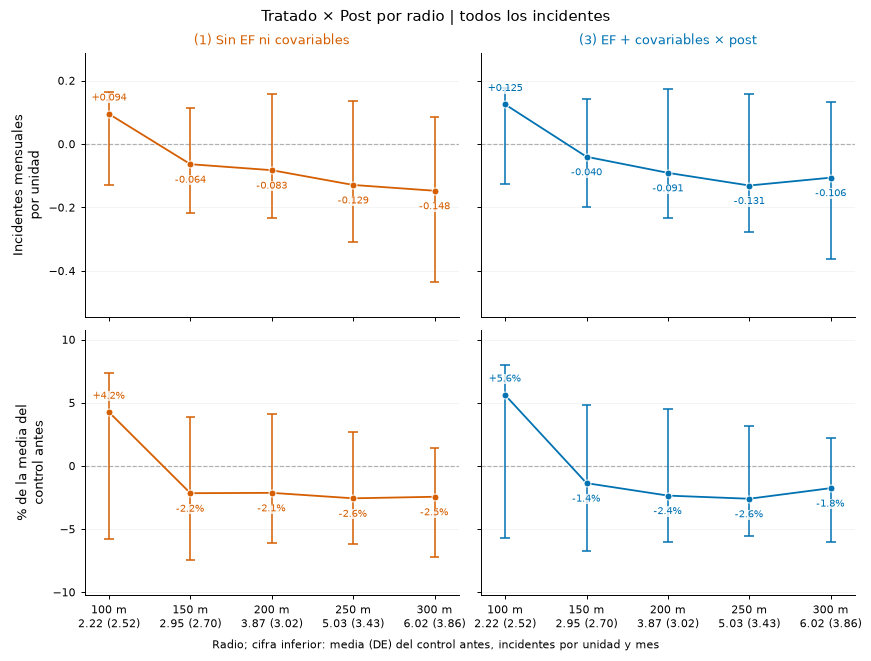

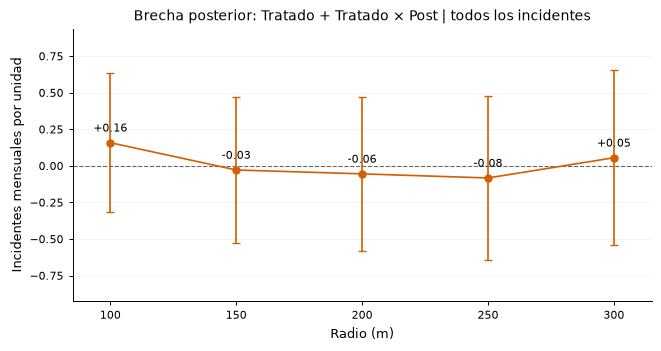

general: figures/efecto-por-radio.png · figures/brecha-posterior.png


In [117]:
graficar_resultados("general", formato="png")

### Incidentes sin lesionados (MIN)

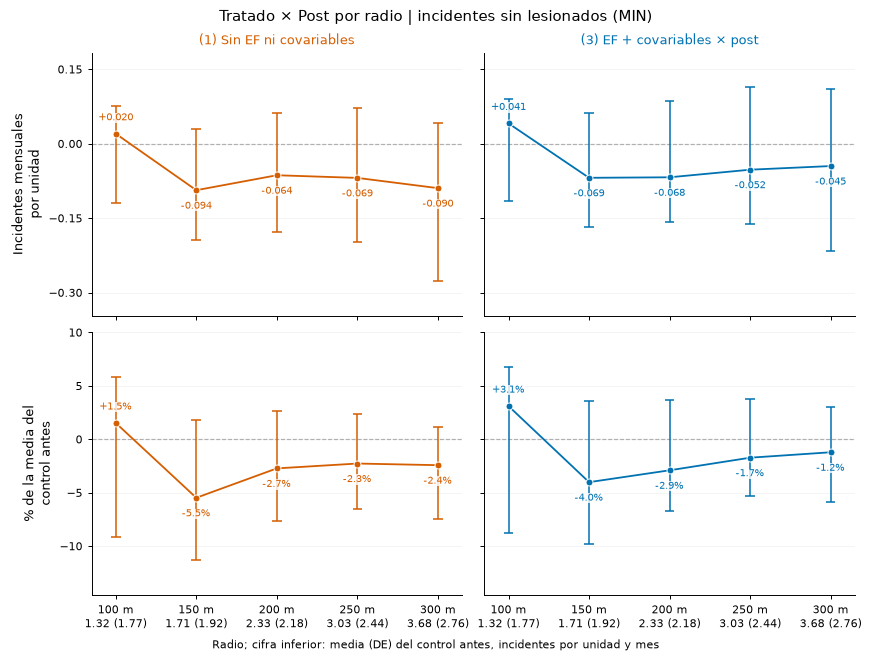

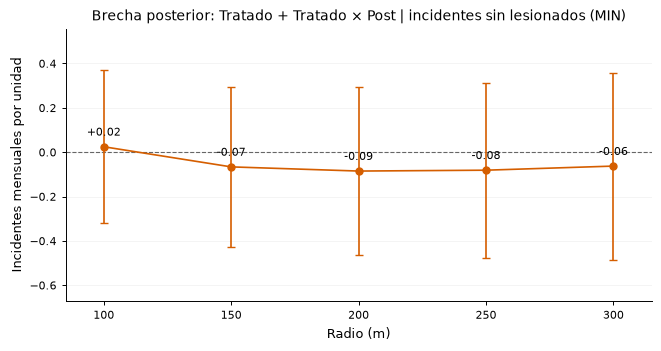

MIN: figures/efecto-por-radio-min.png · figures/brecha-posterior-min.png


In [118]:
graficar_resultados("MIN", formato="png")

### Incidentes con lesionados (PIC)

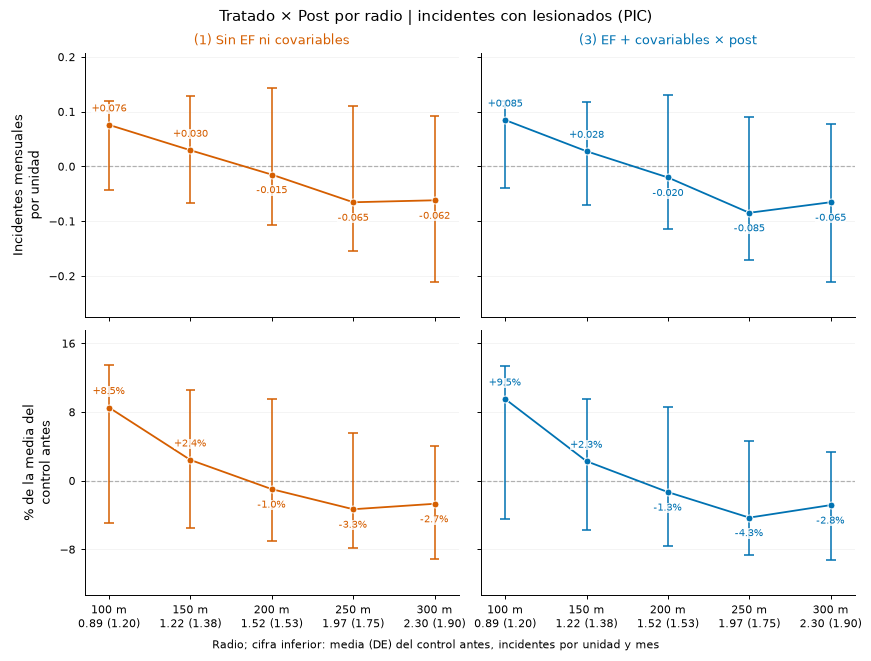

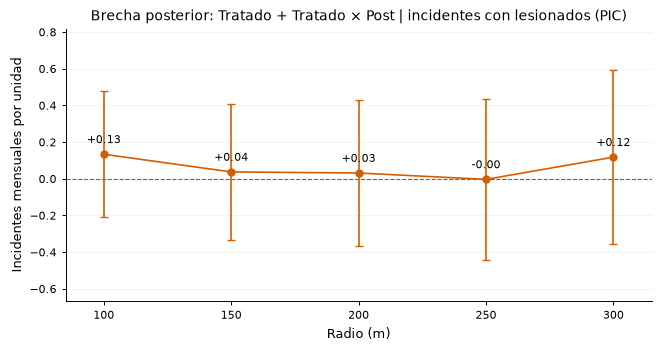

PIC: figures/efecto-por-radio-pic.png · figures/brecha-posterior-pic.png


In [119]:
graficar_resultados("PIC", "png")

### Incidentes fatales (FCS)

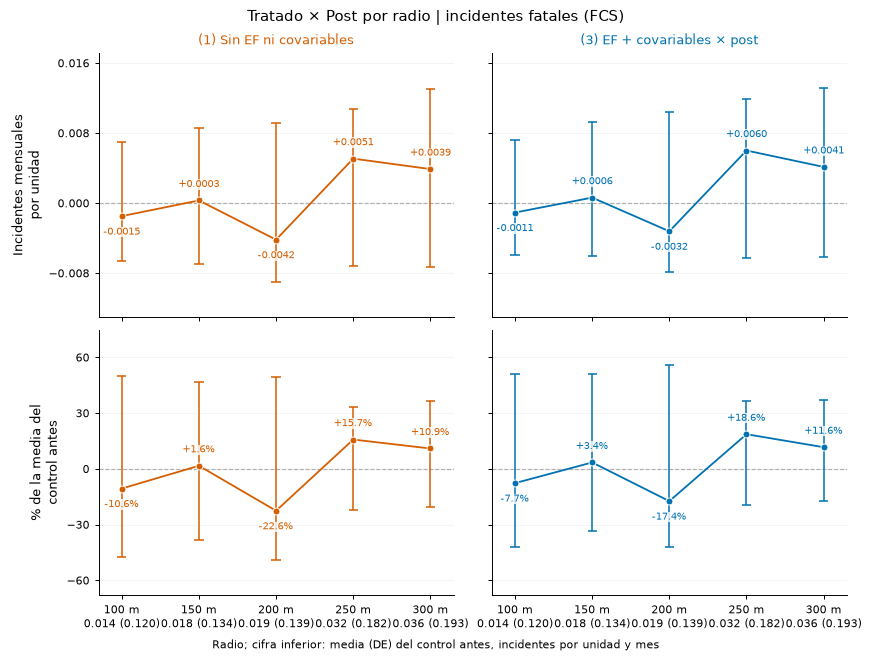

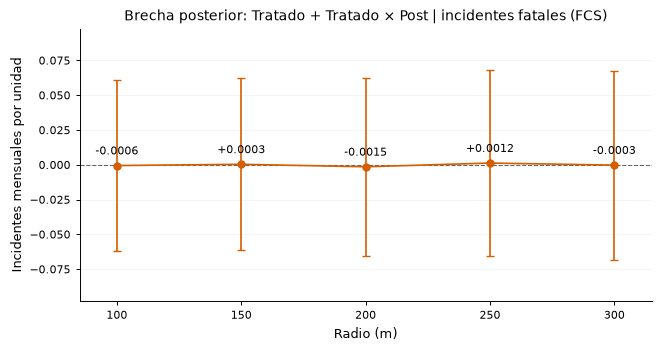

FCS: figures/efecto-por-radio-fcs.png · figures/brecha-posterior-fcs.png


In [120]:
graficar_resultados("FCS", "png")

### Preguntas para interpretar

Para **cada resultado y radio**:

6. ¿Cuál es el signo y la magnitud del coeficiente Tratado × Post, en incidentes por unidad y mes?
7. ¿Cuánto representa ese coeficiente respecto de la media previa del control en ese mismo radio? ¿Qué tan dispersos eran los conteos del control?
8. ¿Cómo cambian el coeficiente y su incertidumbre entre 100 y 300 metros? ¿Estamos comparando la misma muestra tratada?
9. ¿Qué valores incluye el intervalo del bootstrap? ¿Incluye cero? Aunque lo incluya, ¿qué magnitudes siguen siendo compatibles con los datos?
10. ¿Qué permite decir el resultado sobre **todos los incidentes** y qué cambia al mirar MIN, PIC y FCS por separado?
11. Para FCS, ¿el intervalo permite distinguir un efecto pequeño de la falta de precisión?
12. En el modelo (1), ¿cuál es la brecha entre tratadas y controles después del tratamiento? ¿Cómo se diferencia esa brecha del efecto DiD?

Para cerrar la interpretación:

13. ¿Se mantienen el signo y una magnitud parecida en las especificaciones principales?
14. ¿Qué cambia en los análisis de sensibilidad del apéndice: sin matching, con trimming laxo y con otro umbral de fusión?
15. ¿Qué conclusión sostienen **en conjunto** los tamaños estimados y sus intervalos, sin convertir «no significativo» en «efecto nulo»?
16. ¿En qué se parecen o difieren esas magnitudes de los estudios sobre México que citas, una vez puestas en unidades comparables?